# RCEMIP-II 3D budget checks.

Coarse (8 x 8) hourly output. All dumped fields are instantaneous at the output time `t1`.

**Closure**, using dumped fields only, with adv+diff from the divergence of the dumped fluxes:
- `thl_tend(t1)` vs the sum of adv+diff, radiation (lw+sw) and micro.
- `qt_tend(t1)` vs the sum of adv+diff and micro.

The buffer (above 24.3 km) and limiter tendencies aren't dumped.

In [1]:
%matplotlib ipympl

import matplotlib.pyplot as plt
import numpy as np

In [2]:
path = '/home/bart/meteo/projects_maq/2026_connecting_the_clouds/rcemip_ii_case_production/experiments/dev'

itot = 128
jtot = 64
ktot = 128

ratio_x = 8
ratio_y = 8

itot_c = itot // ratio_x
jtot_c = jtot // ratio_y

xsize = 51200
ysize = 25600
zsize = 32343.68603421053

dx_c = xsize / itot_c
dy_c = ysize / jtot_c

float_type = np.float32

t1 = 172800

k = 3

grid = np.fromfile(f'{path}/grid.0000000', dtype=float_type)
z  = grid[2*itot+2*jtot : 2*itot+2*jtot+ktot]
zh = np.append(grid[2*itot+2*jtot+ktot :], zsize)
dz = zh[1:] - zh[:-1]

rho = np.fromfile(f'{path}/rhoref.0000000', dtype=float_type)
rhoref  = rho[:ktot]
rhorefh = rho[ktot:]

def load_c(name, time):
    return np.fromfile(f'{path}/{name}_c.{time:07d}', dtype=float_type).reshape((ktot, jtot_c, itot_c))

def flux_div(scalar, time):
    us = load_c(f'u{scalar}', time)
    vs = load_c(f'v{scalar}', time)
    ws = np.concatenate([load_c(f'w{scalar}', time), np.zeros((1, jtot_c, itot_c))], axis=0)
    return (
        - (np.roll(us, -1, axis=2) - us) / dx_c
        - (np.roll(vs, -1, axis=1) - vs) / dy_c
        - (rhorefh[1:,None,None] * ws[1:] - rhorefh[:-1,None,None] * ws[:-1]) / (rhoref[:,None,None] * dz[:,None,None]) )

def hmean(a):
    return a.mean(axis=(1,2))

## Potential temperature

`thl_tend(t1)` vs the sum of adv+diff, radiation (lw+sw) and micro at `t1`.

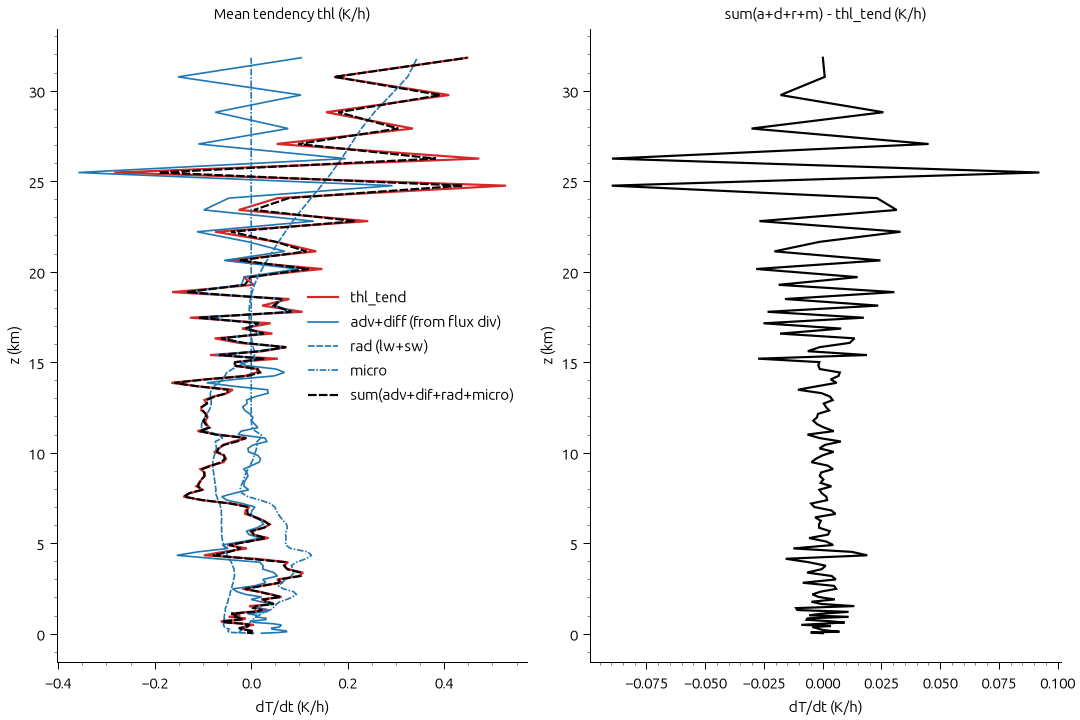

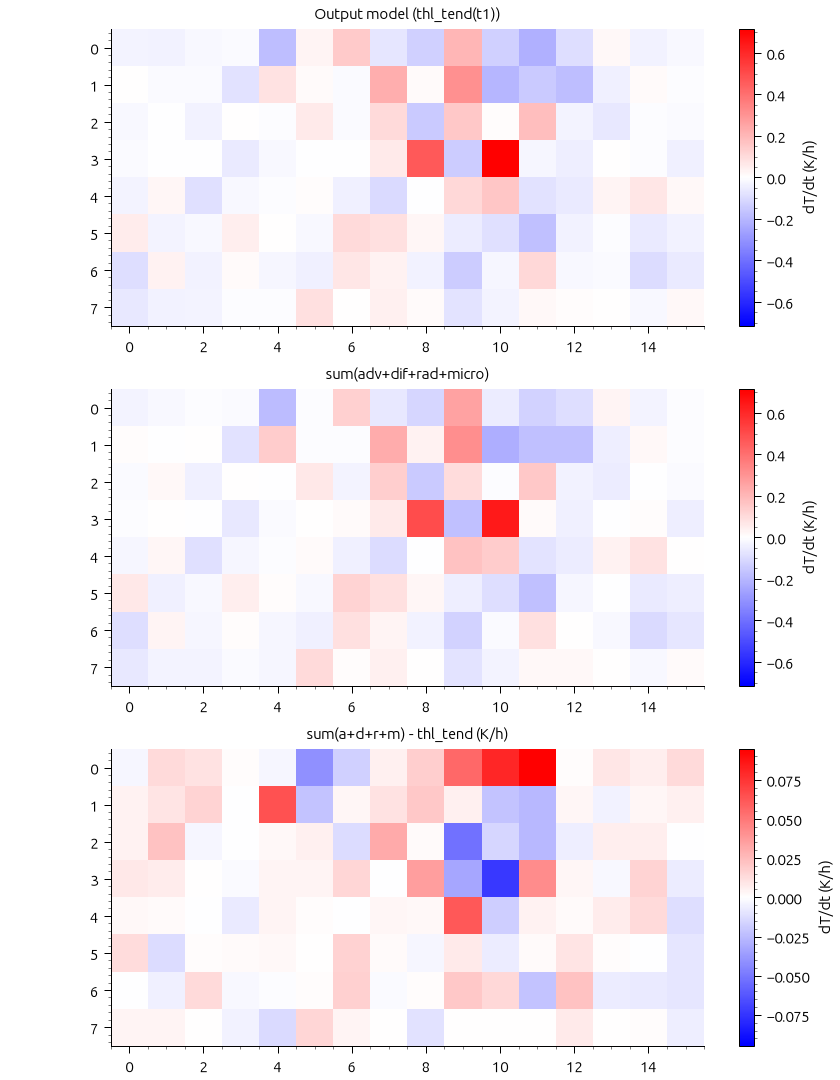

In [3]:
thl_tend = load_c('thl_tend', t1)

thl_advdiff = flux_div('thl', t1)
thl_rad = load_c('thl_tend_lw', t1) + load_c('thl_tend_sw', t1)
thl_micro = load_c('thl_tend_micro', t1)

thl_recon = thl_advdiff + thl_rad + thl_micro

plt.figure(figsize=(9,6), layout='constrained')
plt.subplot(121)
plt.title('Mean tendency thl (K/h)')
plt.plot(hmean(thl_tend)*3600, z/1000, '-', color='tab:red', label='thl_tend')
plt.plot(hmean(thl_advdiff)*3600, z/1000, '-', color='tab:blue', lw=1, label='adv+diff (from flux div)')
plt.plot(hmean(thl_rad)*3600, z/1000, '--', color='tab:blue', lw=1, label='rad (lw+sw)')
plt.plot(hmean(thl_micro)*3600, z/1000, '-.', color='tab:blue', lw=1, label='micro')
plt.plot(hmean(thl_recon)*3600, z/1000, '--', color='k', label='sum(adv+dif+rad+micro)')
plt.xlabel('dT/dt (K/h)')
plt.ylabel('z (km)')
plt.legend()

plt.subplot(122)
plt.title('sum(a+d+r+m) - thl_tend (K/h)')
plt.plot(hmean(thl_recon - thl_tend)*3600, z/1000, '-', color='k')
plt.xlabel('dT/dt (K/h)')
plt.ylabel('z (km)')

vmax = max(np.abs(thl_tend[k]).max(), np.abs(thl_recon[k]).max()) * 3600
vmin = -vmax
vdiff = np.abs(thl_recon[k] - thl_tend[k]).max() * 3600

plt.figure(figsize=(7,9), layout='constrained')
plt.subplot(311)
plt.title('Output model (thl_tend(t1))')
plt.imshow(thl_tend[k]*3600, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

plt.subplot(312)
plt.title('sum(adv+dif+rad+micro)')
plt.imshow(thl_recon[k]*3600, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

plt.subplot(313)
plt.title('sum(a+d+r+m) - thl_tend (K/h)')
plt.imshow((thl_recon[k] - thl_tend[k])*3600, vmin=-vdiff, vmax=vdiff, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

## Moisture

`qt_tend(t1)` vs the sum of adv+diff and micro at `t1`.

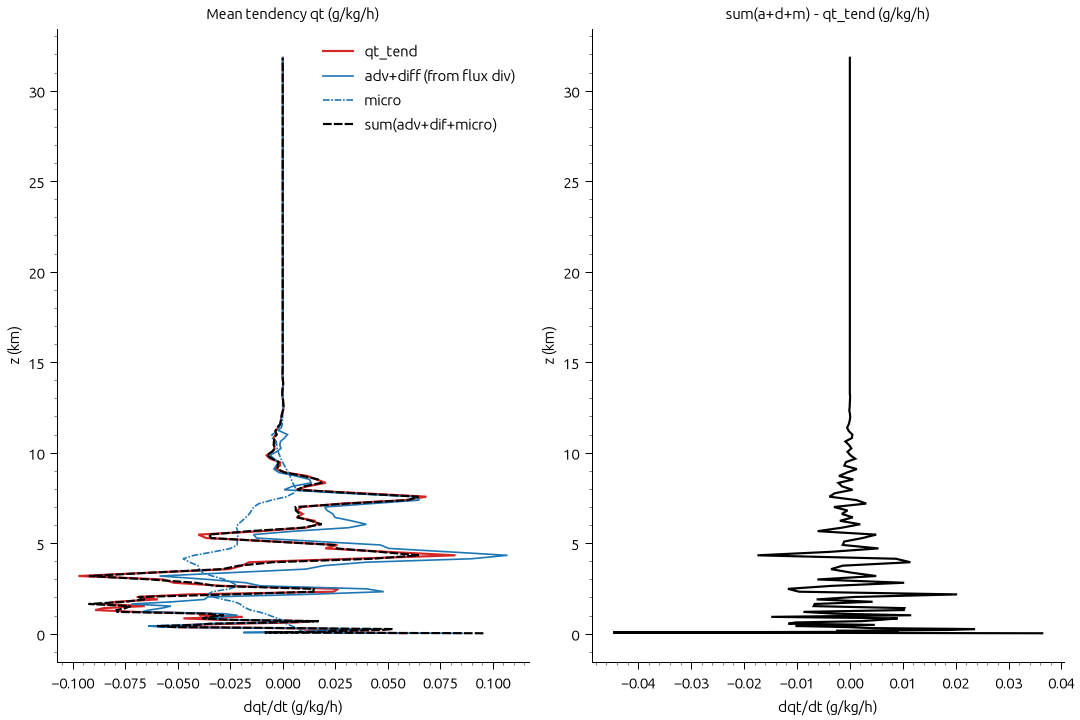

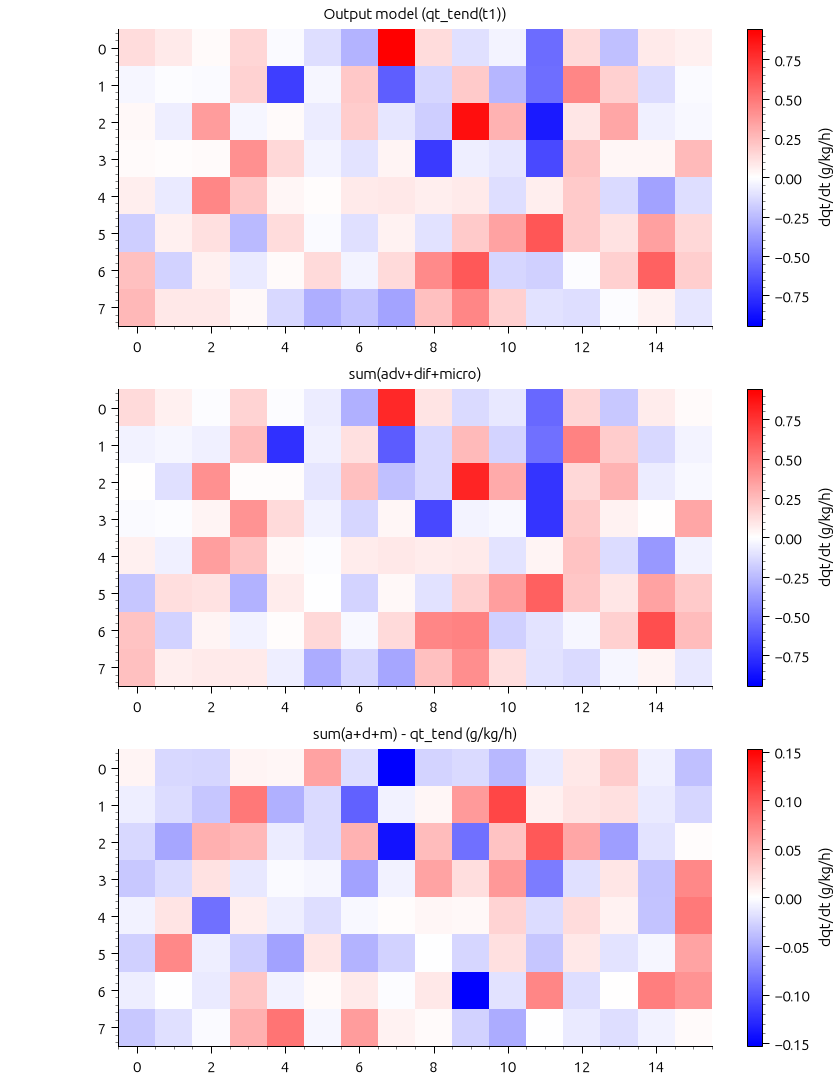

In [4]:
qt_tend = load_c('qt_tend', t1)

qt_advdiff = flux_div('qt', t1)
qt_micro = load_c('qt_tend_micro', t1)

qt_recon = qt_advdiff + qt_micro

plt.figure(figsize=(9,6), layout='constrained')
plt.subplot(121)
plt.title('Mean tendency qt (g/kg/h)')
plt.plot(hmean(qt_tend)*3600e3, z/1000, '-', color='tab:red', label='qt_tend')
plt.plot(hmean(qt_advdiff)*3600e3, z/1000, '-', color='tab:blue', lw=1, label='adv+diff (from flux div)')
plt.plot(hmean(qt_micro)*3600e3, z/1000, '-.', color='tab:blue', lw=1, label='micro')
plt.plot(hmean(qt_recon)*3600e3, z/1000, '--', color='k', label='sum(adv+dif+micro)')
plt.xlabel('dqt/dt (g/kg/h)')
plt.ylabel('z (km)')
plt.legend()

plt.subplot(122)
plt.title('sum(a+d+m) - qt_tend (g/kg/h)')
plt.plot(hmean(qt_recon - qt_tend)*3600e3, z/1000, '-', color='k')
plt.xlabel('dqt/dt (g/kg/h)')
plt.ylabel('z (km)')

vmax = max(np.abs(qt_tend[k]).max(), np.abs(qt_recon[k]).max()) * 3600e3
vmin = -vmax
vdiff = np.abs(qt_recon[k] - qt_tend[k]).max() * 3600e3

plt.figure(figsize=(7,9), layout='constrained')
plt.subplot(311)
plt.title('Output model (qt_tend(t1))')
plt.imshow(qt_tend[k]*3600e3, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dqt/dt (g/kg/h)')

plt.subplot(312)
plt.title('sum(adv+dif+micro)')
plt.imshow(qt_recon[k]*3600e3, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dqt/dt (g/kg/h)')

plt.subplot(313)
plt.title('sum(a+d+m) - qt_tend (g/kg/h)')
plt.imshow((qt_recon[k] - qt_tend[k])*3600e3, vmin=-vdiff, vmax=vdiff, cmap=plt.cm.bwr)
plt.colorbar(label='dqt/dt (g/kg/h)')